# Understanding Bird Breeding in NSW — Five Questions for Conservation

**Purpose.** Use the combined Atlas + DES breeding dataset to find early warning signs that a bird species
may be heading towards trouble — and to point to *who*, *where* and *when* conservation effort would help most.

**How this notebook is laid out.** Each section follows the same pattern:

> **Research question → How we measured it → Answer via visual → What it means**

| # | Research question | Angle |
|---|---|---|
| Q1 | Which species are being **seen less often *and* breeding less** when they are seen? | *Who* needs attention |
| Q2 | **Where** in NSW has breeding activity faded the most, and where is it holding up? | *Where* to act |
| Q3 | **When** in the year is breeding at its busiest — and when is the quiet window for disturbance? | *When* to act |
| Q4 | Are birds of the **inland** faring worse than coastal and tablelands birds? | *Which group* is most at risk |
| Q5 | Are we still **monitoring enough** to notice a species in decline? | Can we *see* the problem |

A client-ready PDF of the same results (no code) is written at the end of the notebook.

*Associations only — these results show patterns in the records, not proven causes.*

## 0. Settings you can customise
Change any value below and re-run the notebook (**Kernel → Restart & Run All**). Every number, chart and
sentence in the notebook and the PDF is recalculated from these settings.

In [1]:
from pathlib import Path
import textwrap, warnings
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
import matplotlib.patheffects
from matplotlib.patches import Rectangle, Patch
from matplotlib.backends.backend_pdf import PdfPages
from scipy.stats import binom
from IPython.display import Markdown, display

warnings.filterwarnings("ignore", category=FutureWarning)

# ---------------- CUSTOMISE HERE ----------------
DATA_PATH = next(p for p in [Path("combined_atlas_des.parquet"), Path("../combined_atlas_des.parquet")] if p.exists())
OUTPUT_DIR = Path("outputs")                 # charts, tables and the PDF are saved here
PDF_NAME = "Bird_Breeding_Insights_Report.pdf"
REPORT_TITLE = "Understanding Bird Breeding in NSW"
REPORT_SUBTITLE = "Five questions to help prevent species decline"
PREPARED_FOR = "Client briefing"
PREPARED_BY = "CS-13 Combined Breeding Analysis team"

EARLY = (1977, 1999)            # historical period (Atlas)
RECENT = (2000, 2020)           # recent period (Atlas; Atlas ends March 2020)

# Q1 / Q4 - which species are included and what counts as a warning sign
MIN_SIGHTINGS = 300             # survey sheets with the species, in EACH period
MIN_EARLY_BREEDING = 30         # breeding records in the early period
WATCH_SEEN = 0.80               # seen at least 20% less often than a typical species ...
WATCH_BREED = 0.60              # ... AND breeding share at least 40% below a typical species
FDR = 0.05                      # false-discovery rate for "clear" (not chance) breeding drops

# Q2 - map cells
CELL_DEG = 0.5                  # map cell size in degrees (0.5 = about 55 km)
MIN_CELL_SHEETS = 40            # survey sheets needed in a cell in EACH period

# Q3 - breeding calendar
ACTIVE_FRACTION = 0.5           # a month is "active" for a species if its breeding rate is >= 50% of its peak month
MIN_ZONE_BREEDING = 20          # breeding records a species needs in a zone to be counted there
QUIET_THRESHOLD = 10            # % of species active, below which a month counts as "quiet"

# Zones used by the team (Coast = NC, CSC, TS; Tablelands = T, NTE; Inland = WS, CP, RP, A, MAW)
ZONES = {"NC": "Coast", "CSC": "Coast", "TS": "Coast", "T": "Tablelands", "NTE": "Tablelands",
         "WS": "Inland", "CP": "Inland", "RP": "Inland", "A": "Inland", "MAW": "Inland"}
ZONE_ORDER = ["Coast", "Tablelands", "Inland"]
# ------------------------------------------------

OUTPUT_DIR.mkdir(exist_ok=True)
print("Data file:", DATA_PATH.resolve())

Data file: C:\Users\pup\Documents\Work\Code\capstone\combined_atlas_des.parquet


In [2]:
# ---- Chart style (validated colour-blind-safe palette) ----
INK, INK2, MUTED, GRID, SURFACE = "#0b0b0b", "#52514e", "#8c8b86", "#e6e5e1", "#ffffff"
BLUE, ORANGE, RED, GREY_PT = "#2a78d6", "#eb6834", "#e34948", "#bdbcb6"
DIV = {"much_less": "#d43d3c", "less": "#f4a7a6", "typical": "#e6e5e1", "more": "#86b6ef", "much_more": "#256abf"}
SEQ = ["#ffffff", "#cde2fb", "#9ec5f4", "#6da7ec", "#3987e5", "#256abf", "#184f95", "#0d366b"]

mpl.rcParams.update({
    "font.family": ["Segoe UI", "DejaVu Sans"], "font.size": 9.5, "text.color": INK,
    "axes.edgecolor": GRID, "axes.labelcolor": INK2, "axes.titlecolor": INK, "axes.linewidth": 0.8,
    "xtick.color": INK2, "ytick.color": INK2, "xtick.major.size": 0, "ytick.major.size": 0,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.spines.top": False, "axes.spines.right": False,
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "figure.dpi": 110, "pdf.fonttype": 42, "legend.frameon": False,
})
CHART_SIZE = (8.27, 5.4)        # same shape as the chart area on a PDF page

def headline(fig, title, subtitle):
    # Takeaway title and plain-language subtitle at the top of a chart region
    fig.text(0.07, 0.975, title, ha="left", va="top", fontsize=13, fontweight="bold", color=INK)
    fig.text(0.07, 0.915, subtitle, ha="left", va="top", fontsize=9.5, color=INK2)

def show(chart, name):
    fig = plt.figure(figsize=CHART_SIZE)
    chart(fig)
    fig.savefig(OUTPUT_DIR / f"{name}.png", dpi=200)
    plt.show()

def tidy_name(n):
    return n.title() if isinstance(n, str) and n.isupper() else n

## 1. Load and prepare the data
**What we keep.** Only rows marked `usable` (bad dates and duplicate DES copies are set aside, as agreed).
Reporting rates use **surveys only** — collections (incidental records) are excluded because they make up
58% of early Atlas sheets but under 3% after 2000, so including them would distort any comparison over time.

**Why most comparisons use the Atlas only.** The Atlas and DES record breeding at different rates, so their
rates are never pooled. Q1–Q4 compare the Atlas with itself (1977–1999 vs 2000–2020). DES is used in Q5,
where we only count surveys and observers.

**A fair comparison.** Across *all* species, the share of sightings recorded as breeding roughly halved between
the two periods — most likely a change in how observers recorded breeding, not a halving of breeding itself.
So every species is compared with the **typical species**: a value of 1 means "changed the same as most birds";
0.5 means "half as much as most birds".

In [3]:
cols = ["source", "sheet_id", "species_id", "common_name", "breeding", "is_collection", "year", "month",
        "single_month", "klat", "klon", "region", "observer_id", "usable"]
raw = pd.read_parquet(DATA_PATH, columns=cols)
for c in ["source", "sheet_id", "common_name", "region", "observer_id"]:
    raw[c] = raw[c].astype("category")
data = raw[raw["usable"]].copy()
del raw

data["zone"] = data["region"].astype(str).map(ZONES)
# Ten-minute grid codes (e.g. 3315 = 33 deg 15 min) -> decimal degrees
data["lat"] = -(data["klat"] // 100 + (data["klat"] % 100) / 60)
data["lon"] = data["klon"] // 100 + (data["klon"] % 100) / 60
in_nsw = data["lat"].between(-37.7, -28.0) & data["lon"].between(140.9, 153.7)

surveys = data[~data["is_collection"] & in_nsw]
atlas = surveys[(surveys["source"] == "Atlas") & surveys["year"].between(EARLY[0], RECENT[1])].copy()
atlas["period"] = np.where(atlas["year"] <= EARLY[1], "early", "recent")
names = data.drop_duplicates("species_id").set_index("species_id")["common_name"].astype(str).map(tidy_name)

overview = data.groupby("source", observed=True).agg(
    records=("species_id", "size"), sheets=("sheet_id", "nunique"), species=("species_id", "nunique"),
    breeding_records=("breeding", "sum"), first_year=("year", "min"), last_year=("year", "max"))
display(overview.style.format("{:,.0f}"))
print(f"Atlas surveys used for comparisons: {atlas['sheet_id'].nunique():,} sheets "
      f"({(atlas['period'] == 'early').sum():,} early rows, {(atlas['period'] == 'recent').sum():,} recent rows)")

,records,sheets,species,breeding_records,first_year,last_year
source,,,,,,
Atlas,"6,531,324","573,198",631,"339,953","1,900","2,020"
DES,"102,701","2,552",415,"2,297","1,976","2,026"


Atlas surveys used for comparisons: 245,546 sheets (3,171,770 early rows, 2,356,073 recent rows)


---
## Q1. Which species are being seen less often *and* breeding less when they are seen?

**Why ask this.** A species can decline in two ways that need different responses:
* **Seen less** → fewer birds or a shrinking range.
* **Breeding less when seen** → birds are still there but not raising young — an *early* warning, because
  adults can live for years after breeding fails.

A species doing badly on **both** counts is a strong candidate for a watchlist.

**How we measured it.**
* *How often seen* = share of survey sheets that record the species (balanced across Coast, Tablelands and
  Inland so that a shift in where people surveyed does not distort the result).
* *Breeding share* = of the sheets where the species was seen, the share with breeding evidence.
* Both are shown relative to the typical species (1 = typical change).
* A breeding drop is called **clear** only if it is unlikely to be chance, after allowing for testing many species.

In [4]:
q1 = atlas[atlas["zone"].notna()]
effort = q1.drop_duplicates("sheet_id").groupby(["period", "zone"]).size()
zone_weight = effort["early"] / effort["early"].sum()       # balance zones to the early survey mix

g = q1.groupby(["species_id", "period", "zone"], observed=True).agg(
    seen=("breeding", "size"), bred=("breeding", "sum")).reset_index()
g["effort"] = effort.reindex(pd.MultiIndex.from_arrays([g["period"], g["zone"]])).values
g["w"] = g["zone"].map(zone_weight)
g["seen_w"] = g["seen"] / g["effort"] * g["w"]
g["bred_w"] = g["bred"] / g["effort"] * g["w"]

sp = g.groupby(["species_id", "period"])[["seen", "bred", "seen_w", "bred_w"]].sum().unstack("period", fill_value=0)
sp.columns = [f"{a}_{b}" for a, b in sp.columns]
sp = sp[(sp["seen_early"] >= MIN_SIGHTINGS) & (sp["seen_recent"] >= MIN_SIGHTINGS)
        & (sp["bred_early"] >= MIN_EARLY_BREEDING)].copy()
sp["name"] = names.reindex(sp.index)
sp["seen_change"] = sp["seen_w_recent"] / sp["seen_w_early"]
sp["share_change"] = (sp["bred_w_recent"] / sp["seen_w_recent"]) / (sp["bred_w_early"] / sp["seen_w_early"])
TYP_SEEN, TYP_SHARE = sp["seen_change"].median(), sp["share_change"].median()
sp["rel_seen"] = sp["seen_change"] / TYP_SEEN
sp["rel_breed"] = sp["share_change"] / TYP_SHARE

# Is the breeding drop more than chance? (one-sided binomial test vs the typical species, Benjamini-Hochberg)
expected_share = (sp["bred_early"] / sp["seen_early"] * TYP_SHARE).clip(upper=1)
sp["p"] = binom.cdf(sp["bred_recent"], sp["seen_recent"], expected_share)
ps = sp["p"].sort_values()
sp["q"] = (ps * len(ps) / np.arange(1, len(ps) + 1))[::-1].cummin()[::-1].clip(upper=1).reindex(sp.index)
sp["clear_drop"] = sp["q"] < FDR

# Home zone = the zone where the species was reported most often in the early period (used again in Q4)
early_rate = (q1[q1["period"] == "early"].groupby(["species_id", "zone"], observed=True).size()
              .unstack(fill_value=0).div(effort["early"]))
sp["home"] = early_rate.reindex(sp.index).idxmax(axis=1)

watch = sp[(sp["rel_seen"] < WATCH_SEEN) & (sp["rel_breed"] < WATCH_BREED) & sp["clear_drop"]]
watch = watch.sort_values("rel_breed")
watch_table = watch[["name", "seen_early", "seen_recent", "bred_early", "bred_recent", "rel_seen", "rel_breed"]].rename(
    columns={"name": "Species", "seen_early": "Sightings 1977-99", "seen_recent": "Sightings 2000-20",
             "bred_early": "Breeding records 1977-99", "bred_recent": "Breeding records 2000-20",
             "rel_seen": "Seen vs typical", "rel_breed": "Breeding vs typical"})
watch_table.to_csv(OUTPUT_DIR / "Q1_watchlist.csv", index=False)
sp.to_csv(OUTPUT_DIR / "Q1_all_species.csv")

print(f"{len(sp)} species have enough records. Typical species: seen x{TYP_SEEN:.2f}, breeding share x{TYP_SHARE:.2f}.")
print(f"{sp['clear_drop'].sum()} species show a clear breeding drop; {len(watch)} also seen clearly less often -> watchlist.")
display(watch_table.style.format({c: "{:,.0f}" for c in watch_table.columns[1:5]} |
                                 {"Seen vs typical": "{:.2f}", "Breeding vs typical": "{:.2f}"}).hide(axis="index"))

273 species have enough records. Typical species: seen x0.82, breeding share x0.51.
62 species show a clear breeding drop; 12 also seen clearly less often -> watchlist.


Species,Sightings 1977-99,Sightings 2000-20,Breeding records 1977-99,Breeding records 2000-20,Seen vs typical,Breeding vs typical
Masked Woodswallow,"2,103",997,123,7,0.80,0.25
Brown Songlark,"4,296","1,676",74,4,0.67,0.27
Superb Lyrebird,"6,733","3,410",107,8,0.69,0.29
Splendid Fairy-wren,"1,319",489,70,4,0.65,0.30
Crested Bellbird,"2,909","1,249",58,4,0.76,0.31
White-backed Swallow,"2,503",872,94,7,0.60,0.38
Australasian Pipit,"23,301","9,696",433,46,0.62,0.49
Crimson Chat,"1,330",568,131,14,0.75,0.49
White-throated Treecreeper,"26,390","14,719",304,47,0.80,0.53
Southern Whiteface,"6,923","2,491",313,32,0.63,0.56


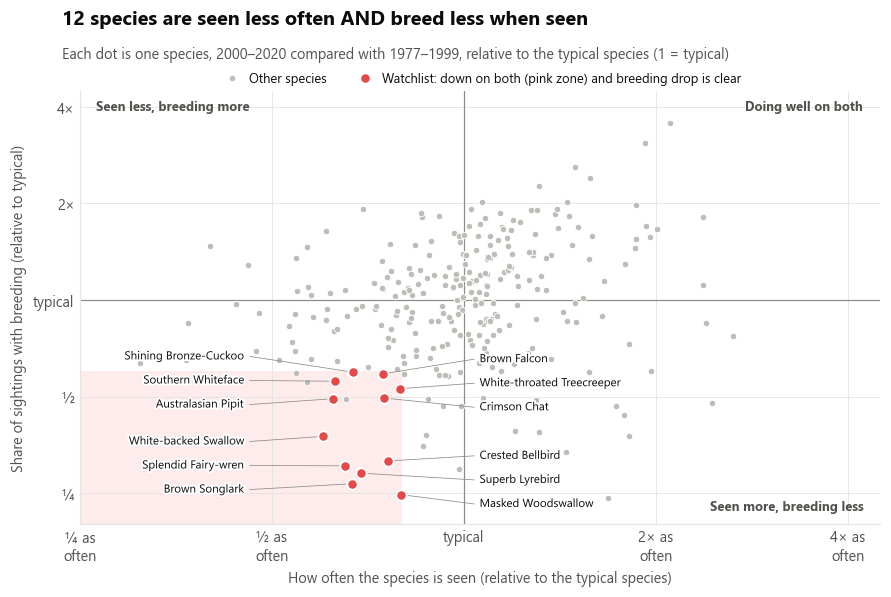

In [5]:
def chart_q1(fig):
    headline(fig, f"{len(watch)} species are seen less often AND breed less when seen",
             "Each dot is one species, 2000–2020 compared with 1977–1999, relative to the typical species (1 = typical)")
    ax = fig.add_gridspec(1, 1, left=0.09, right=0.97, top=0.84, bottom=0.11).subplots()
    lo_x, hi_x = 0.25, 4.5
    lo_y, hi_y = 0.2, 4.5
    ax.add_patch(Rectangle((lo_x, lo_y), WATCH_SEEN - lo_x, WATCH_BREED - lo_y, color="#fdeceb", zorder=0, lw=0))
    ax.axvline(1, color=MUTED, lw=0.8, zorder=1)
    ax.axhline(1, color=MUTED, lw=0.8, zorder=1)
    rest = sp.drop(watch.index)
    ax.scatter(rest["rel_seen"], rest["rel_breed"], s=18, color=GREY_PT, edgecolor="white", lw=0.6, zorder=2,
               label="Other species")
    ax.scatter(watch["rel_seen"], watch["rel_breed"], s=46, color=RED, edgecolor="white", lw=1.2, zorder=3,
               label="Watchlist: down on both (pink zone) and breeding drop is clear")
    ax.set_xscale("log"); ax.set_yscale("log")
    ticks = [0.25, 0.5, 1, 2, 4]
    lab = ["¼ as\noften", "½ as\noften", "typical", "2× as\noften", "4× as\noften"]
    ax.set_xticks(ticks, lab); ax.set_yticks(ticks, ["¼", "½", "typical", "2×", "4×"])
    ax.minorticks_off()
    ax.set_xlim(lo_x, hi_x); ax.set_ylim(lo_y, hi_y)
    ax.set_xlabel("How often the species is seen (relative to the typical species)")
    ax.set_ylabel("Share of sightings with breeding (relative to typical)")
    kw = dict(fontsize=8.5, color=INK2, fontweight="bold")
    ax.text(lo_x * 1.06, hi_y * 0.93, "Seen less, breeding more", va="top", **kw)
    ax.text(hi_x * 0.94, hi_y * 0.93, "Doing well on both", va="top", ha="right", **kw)
    ax.text(hi_x * 0.94, lo_y * 1.08, "Seen more, breeding less", va="bottom", ha="right", **kw)
    # Watchlist names in two tidy columns either side of the cluster, spaced so they never overlap
    halo = [mpl.patheffects.withStroke(linewidth=2.5, foreground="white")]
    split = np.log10(watch["rel_seen"]).median()
    for side, grp in [("left", watch[np.log10(watch["rel_seen"]) < split]),
                      ("right", watch[np.log10(watch["rel_seen"]) >= split])]:
        grp = grp.sort_values("rel_breed")
        pos = np.log10(grp["rel_breed"]).values.copy()
        for i in range(1, len(pos)):
            pos[i] = max(pos[i], pos[i - 1] + 0.075)
        pos += (np.log10(grp["rel_breed"]).values - pos).mean()
        x_txt = grp["rel_seen"].min() / 1.3 if side == "left" else grp["rel_seen"].max() * 1.3
        for (_, r), yl in zip(grp.iterrows(), 10 ** pos):
            ax.plot([r["rel_seen"], x_txt], [r["rel_breed"], yl], color=MUTED, lw=0.5, zorder=2.5)
            ax.text(x_txt * (0.98 if side == "left" else 1.02), yl, r["name"], fontsize=7.6, color=INK, va="center",
                    ha="right" if side == "left" else "left", zorder=4, path_effects=halo)
    ax.legend(loc="upper center", ncol=2, fontsize=8.5, bbox_to_anchor=(0.5, 1.07), handletextpad=0.3)

show(chart_q1, "Q1_seen_vs_breeding")

In [6]:
n_both_down = ((sp["rel_seen"] < 1) & (sp["rel_breed"] < 1)).sum()
top3 = ", ".join(watch["name"].head(3))
watch_inland = watch[watch["home"] == "Inland"]["name"].tolist()
Q1 = dict(
    question="Which species are being seen less often and breeding less when they are seen?",
    why="A species still being seen but no longer breeding is an early warning: adults can live for years "
        "after breeding fails. Species down on both counts are strong candidates for a conservation watchlist.",
    findings=[
        f"Of {len(sp)} species with enough records, {n_both_down} fall below typical on both measures, but most "
        f"of these are small differences.",
        f"{len(watch)} species stand out: seen at least {100 - WATCH_SEEN * 100:.0f}% less often than a typical bird "
        f"AND breeding share at least {100 - WATCH_BREED * 100:.0f}% lower, with a breeding drop unlikely to be chance.",
        f"The steepest breeding falls are {top3}.",
        f"{len(watch_inland)} of the {len(watch)} are mainly inland birds ({', '.join(watch_inland[:5])}"
        f"{' and others' if len(watch_inland) > 5 else ''}) — Q4 tests whether inland birds as a group are faring worse.",
    ],
    meaning="These species are the best candidates for targeted follow-up: nest monitoring, habitat checks in "
            "their remaining strongholds, and comparison with official threatened-species listings.",
    caveat="Some watchlist species have few recent breeding records, so the size of each change is uncertain. "
           "Results are associations, not proof of cause.",
)
display(Markdown("### Answer\n" + "\n".join(f"* {f}" for f in Q1["findings"]) +
                 f"\n\n**What it means:** {Q1['meaning']}\n\n*Caution: {Q1['caveat']}*"))

### Answer
* Of 273 species with enough records, 83 fall below typical on both measures, but most of these are small differences.
* 12 species stand out: seen at least 20% less often than a typical bird AND breeding share at least 40% lower, with a breeding drop unlikely to be chance.
* The steepest breeding falls are Masked Woodswallow, Brown Songlark, Superb Lyrebird.
* 9 of the 12 are mainly inland birds (Masked Woodswallow, Brown Songlark, Splendid Fairy-wren, Crested Bellbird, White-backed Swallow and others) — Q4 tests whether inland birds as a group are faring worse.

**What it means:** These species are the best candidates for targeted follow-up: nest monitoring, habitat checks in their remaining strongholds, and comparison with official threatened-species listings.

*Caution: Some watchlist species have few recent breeding records, so the size of each change is uncertain. Results are associations, not proof of cause.*

---
## Q2. Where in NSW has breeding activity faded the most, and where is it holding up?

**Why ask this.** Protection is applied to places — reserves, private land agreements, planning controls.
Knowing where breeding has faded (and where it is still strong) shows where to look first.

**How we measured it.** NSW is split into cells of about 55 km. In each cell, *breeding activity* is the number
of breeding records per survey sheet (this allows for how much surveying happened there). Each cell's change is
compared with the state-wide change, so red means "faded more than NSW overall" and blue means "held up better".
Only cells with at least 40 survey sheets in each period are shown.

In [7]:
cells = atlas.assign(cell_lat=np.floor(atlas["lat"] / CELL_DEG) * CELL_DEG,
                     cell_lon=np.floor(atlas["lon"] / CELL_DEG) * CELL_DEG)
cell = cells.groupby(["cell_lat", "cell_lon", "period"]).agg(
    sheets=("sheet_id", "nunique"), bred=("breeding", "sum")).unstack("period", fill_value=0)
cell.columns = [f"{a}_{b}" for a, b in cell.columns]
cell = cell[(cell["sheets_early"] >= MIN_CELL_SHEETS) & (cell["sheets_recent"] >= MIN_CELL_SHEETS)
            & (cell["bred_early"] > 0)].copy()      # a change needs some early breeding to compare against
state = atlas.groupby("period")["breeding"].sum() / atlas.groupby("period")["sheet_id"].nunique()
cell["rel"] = ((cell["bred_recent"] / cell["sheets_recent"]) /
               (cell["bred_early"] / cell["sheets_early"])) / (state["recent"] / state["early"])
cell_zone = (cells.drop_duplicates("sheet_id").groupby(["cell_lat", "cell_lon"])["zone"]
             .agg(lambda s: s.mode().iat[0] if s.notna().any() else np.nan))
cell["zone"] = cell_zone.reindex(cell.index)

BINS = [0, 0.5, 0.8, 1.25, 2, np.inf]
CLASS = ["much_less", "less", "typical", "more", "much_more"]
CLASS_LABEL = ["Faded a lot (under ½ of NSW trend)", "Faded somewhat", "About the NSW trend",
               "Held up better", "Held up much better (over 2×)"]
cell["cls"] = pd.cut(cell["rel"], BINS, labels=CLASS, right=False)
cell.to_csv(OUTPUT_DIR / "Q2_map_cells.csv")

squares = atlas[["lat", "lon"]].drop_duplicates()
faded = cell["cls"].isin(["much_less", "less"])
by_zone = (cell.assign(faded=faded).groupby("zone")["faded"].mean() * 100).reindex(ZONE_ORDER)
print(f"{len(cell)} cells mapped; {faded.mean():.0%} faded more than the NSW trend.")
display(by_zone.round(0).rename("% of cells that faded").to_frame())

241 cells mapped; 57% faded more than the NSW trend.


,% of cells that faded
zone,
Coast,21.0
Tablelands,61.0
Inland,64.0


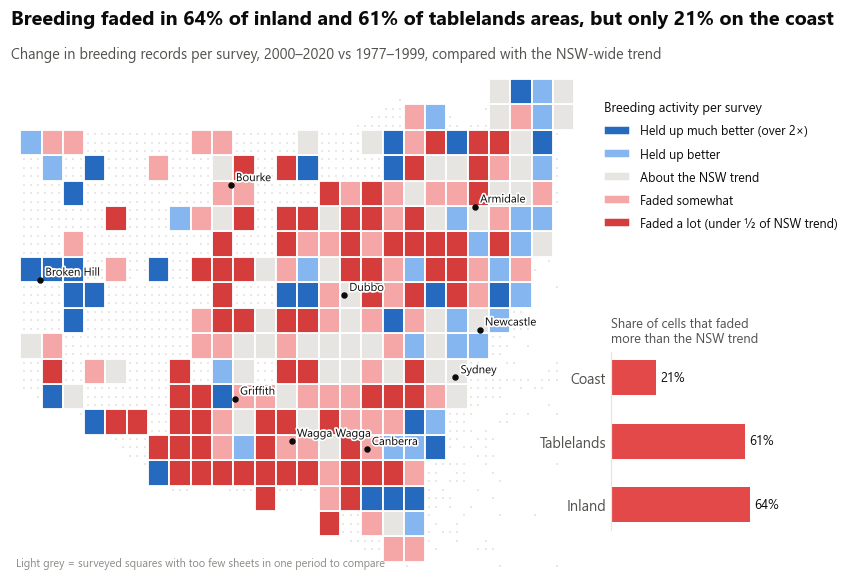

In [8]:
TOWNS = {"Sydney": (-33.87, 151.21), "Newcastle": (-32.93, 151.78), "Canberra": (-35.28, 149.13),
         "Dubbo": (-32.25, 148.60), "Broken Hill": (-31.95, 141.47), "Wagga Wagga": (-35.12, 147.37),
         "Armidale": (-30.51, 151.67), "Bourke": (-30.09, 145.94), "Griffith": (-34.29, 146.04)}

def chart_q2(fig):
    headline(fig, f"Breeding faded in {by_zone['Inland']:.0f}% of inland and {by_zone['Tablelands']:.0f}% of "
                  f"tablelands areas, but only {by_zone['Coast']:.0f}% on the coast",
             "Change in breeding records per survey, 2000–2020 vs 1977–1999, compared with the NSW-wide trend")
    ax = fig.add_gridspec(1, 1, left=0.06, right=0.70, top=0.86, bottom=0.03).subplots()
    ax.scatter(squares["lon"], squares["lat"], s=2.2, marker="s", color="#e9e8e4", lw=0, zorder=0)
    for (la, lo), r in cell.iterrows():
        ax.add_patch(Rectangle((lo, la), CELL_DEG, CELL_DEG, facecolor=DIV[r["cls"]], edgecolor="white", lw=1.2, zorder=1))
    for t, (la, lo) in TOWNS.items():
        ax.plot(lo, la, "o", ms=3.2, color=INK, zorder=3)
        ax.text(lo + 0.12, la + 0.08, t, fontsize=7.5, color=INK, zorder=3,
                path_effects=[mpl.patheffects.withStroke(linewidth=2.2, foreground="white")])
    ax.set_aspect(1 / np.cos(np.radians(33)))
    ax.set_xlim(140.8, 154); ax.set_ylim(-37.7, -28.0)
    ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
    for s in ax.spines.values(): s.set_visible(False)
    ax.text(140.9, -37.6, "Light grey = surveyed squares with too few sheets in one period to compare",
            fontsize=7.2, color=MUTED)
    handles = [Patch(facecolor=DIV[c], edgecolor="white", label=l) for c, l in zip(CLASS[::-1], CLASS_LABEL[::-1])]
    fig.legend(handles=handles, loc="upper left", bbox_to_anchor=(0.71, 0.84), fontsize=8.2,
               title="Breeding activity per survey", title_fontsize=8.5, alignment="left", labelspacing=0.8)
    lax = fig.add_axes([0.73, 0.10, 0.24, 0.30])
    vals = by_zone.values
    lax.barh(range(3), vals, color=RED, height=0.55)
    for i, v in enumerate(vals):
        lax.text(v + 2, i, f"{v:.0f}%", va="center", fontsize=8.5, color=INK)
    lax.set_yticks(range(3), ZONE_ORDER); lax.invert_yaxis()
    lax.set_xlim(0, 100); lax.set_xticks([]); lax.grid(False)
    lax.spines["bottom"].set_visible(False)
    lax.set_title("Share of cells that faded\nmore than the NSW trend", fontsize=8.5, loc="left", color=INK2)

show(chart_q2, "Q2_breeding_map")

In [9]:
held = cell[cell["cls"].isin(["more", "much_more"])]
Q2 = dict(
    question="Where in NSW has breeding activity faded the most, and where is it holding up?",
    why="Protection is applied to places. Knowing where breeding has faded, and where it is still strong, "
        "shows where to look first and which areas may act as refuges.",
    findings=[
        f"Across {len(cell)} well-surveyed cells, {faded.mean():.0%} show breeding activity fading faster than the "
        f"NSW-wide trend.",
        f"By zone: {by_zone['Coast']:.0f}% of coastal cells, {by_zone['Tablelands']:.0f}% of tablelands cells and "
        f"{by_zone['Inland']:.0f}% of inland cells faded more than the state trend.",
        f"{len(held)} cells ({len(held) / len(cell):.0%}) held up better than the state trend — these are candidate "
        f"breeding strongholds worth protecting.",
        "Large parts of the far west have too few surveys in one or both periods to compare (light grey dots).",
    ],
    meaning="Inland and tablelands areas with faded breeding are priority areas to check on the ground; cells that held up are "
            "candidate refuges where protecting habitat may safeguard breeding.",
    caveat="Cells mix many species and observers changed over time; a faded cell is a prompt to investigate, "
           "not proof of habitat loss.",
)
display(Markdown("### Answer\n" + "\n".join(f"* {f}" for f in Q2["findings"]) +
                 f"\n\n**What it means:** {Q2['meaning']}\n\n*Caution: {Q2['caveat']}*"))

### Answer
* Across 241 well-surveyed cells, 57% show breeding activity fading faster than the NSW-wide trend.
* By zone: 21% of coastal cells, 61% of tablelands cells and 64% of inland cells faded more than the state trend.
* 56 cells (23%) held up better than the state trend — these are candidate breeding strongholds worth protecting.
* Large parts of the far west have too few surveys in one or both periods to compare (light grey dots).

**What it means:** Inland and tablelands areas with faded breeding are priority areas to check on the ground; cells that held up are candidate refuges where protecting habitat may safeguard breeding.

*Caution: Cells mix many species and observers changed over time; a faded cell is a prompt to investigate, not proof of habitat loss.*

---
## Q3. When in the year is breeding at its busiest — and when is the quiet window for disturbance?

**Why ask this.** Many activities that disturb nesting birds — hazard-reduction burns, land clearing, tree
lopping, construction — can often be timed. Knowing when *most* species are nesting helps set those windows.

**How we measured it.** Recent Atlas surveys (2000–2020), single-month sheets only. For each species in each
zone we find its peak breeding month; any month where its breeding rate is at least half that peak counts as
"active". The chart shows the share of the zone's breeding species that are active in each month.

In [10]:
# Year shown from August so that the breeding season and the quiet window each read as one block
MONTHS = ["Aug", "Sep", "Oct", "Nov", "Dec", "Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul"]
MONTH_NUM = [8, 9, 10, 11, 12, 1, 2, 3, 4, 5, 6, 7]

q3 = atlas[(atlas["period"] == "recent") & (atlas["single_month"] == True) & atlas["zone"].notna()]
month_effort = q3.drop_duplicates("sheet_id").groupby(["zone", "month"]).size()
br = q3[q3["breeding"]].groupby(["zone", "species_id", "month"], observed=True).size().rename("n").reset_index()
br["rate"] = br["n"] / month_effort.reindex(pd.MultiIndex.from_arrays([br["zone"], br["month"]])).values
enough = br.groupby(["zone", "species_id"])["n"].transform("sum") >= MIN_ZONE_BREEDING
br = br[enough].copy()
br["active"] = br["rate"] >= ACTIVE_FRACTION * br.groupby(["zone", "species_id"])["rate"].transform("max")
n_species = br.groupby("zone")["species_id"].nunique().reindex(ZONE_ORDER)
cal = (br[br["active"]].groupby(["zone", "month"])["species_id"].nunique().unstack(fill_value=0)
       .reindex(index=ZONE_ORDER, columns=MONTH_NUM, fill_value=0))
cal_pct = cal.div(n_species, axis=0) * 100
cal_pct.columns = MONTHS
cal_pct.round(1).to_csv(OUTPUT_DIR / "Q3_breeding_calendar.csv")

quiet = [m for m in MONTHS if (cal_pct[m] < QUIET_THRESHOLD).all()]
peak_month = cal_pct.mean().idxmax()
busy = [m for m in MONTHS if (cal_pct[m] >= 50).any()]
display(cal_pct.round(0).astype(int).style.background_gradient(cmap="Blues", axis=None))
print("Quiet months (all zones <", QUIET_THRESHOLD, "%):", quiet, "| Busiest month:", peak_month, "| 50%+ in any zone:", busy)

,Aug,Sep,Oct,Nov,Dec,Jan,Feb,Mar,Apr,May,Jun,Jul
zone,,,,,,,,,,,,
Coast,14,34,58,71,78,64,20,10,5,3,2,5
Tablelands,11,33,68,79,72,60,36,5,1,2,1,1
Inland,21,34,55,75,79,44,26,3,1,0,1,5


Quiet months (all zones < 10 %): ['Mar', 'Apr', 'May', 'Jun', 'Jul'] | Busiest month: Dec | 50%+ in any zone: ['Oct', 'Nov', 'Dec', 'Jan']


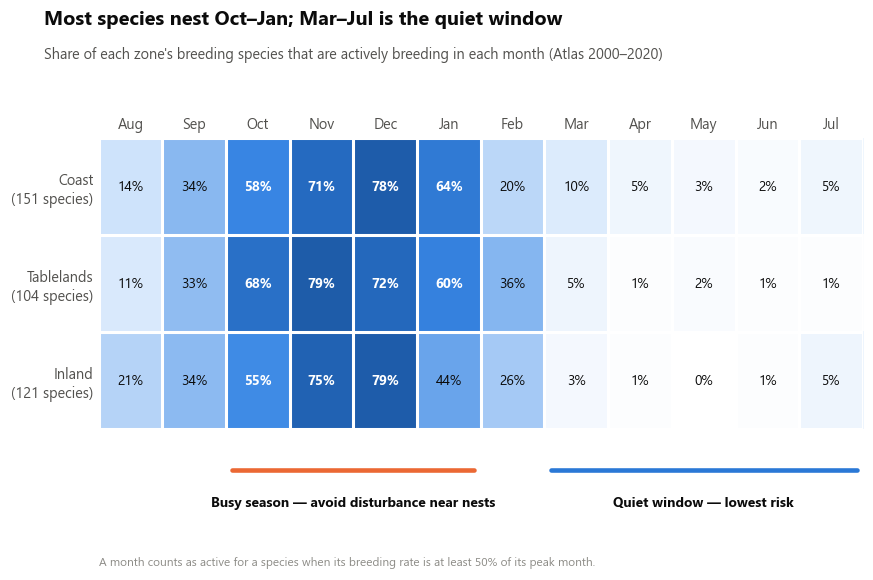

In [11]:
def chart_q3(fig):
    headline(fig, f"Most species nest {busy[0]}–{busy[-1]}; {quiet[0]}–{quiet[-1]} is the quiet window",
             "Share of each zone's breeding species that are actively breeding in each month (Atlas 2000–2020)")
    ax = fig.add_gridspec(1, 1, left=0.13, right=0.97, top=0.76, bottom=0.27).subplots()
    cmap = mpl.colors.LinearSegmentedColormap.from_list("seq", SEQ)
    ax.imshow(cal_pct.values, cmap=cmap, vmin=0, vmax=100, aspect="auto")
    for i in range(cal_pct.shape[0]):
        for j in range(cal_pct.shape[1]):
            v = cal_pct.values[i, j]
            ax.text(j, i, f"{v:.0f}%", ha="center", va="center", fontsize=9,
                    color="white" if v >= 45 else INK, fontweight="bold" if v >= 50 else "normal")
    ax.set_xticks(range(12), MONTHS); ax.set_yticks(range(3), [f"{z}\n({n_species[z]} species)" for z in ZONE_ORDER])
    ax.xaxis.tick_top(); ax.grid(False)
    for s in ax.spines.values(): s.set_visible(False)
    ax.set_xticks(np.arange(-0.5, 12), minor=True); ax.set_yticks(np.arange(-0.5, 3), minor=True)
    ax.grid(which="minor", color="white", lw=2); ax.tick_params(which="minor", length=0)
    # brackets for the busy season and the quiet window
    b0, b1 = MONTHS.index(busy[0]), MONTHS.index(busy[-1])
    q0, q1 = MONTHS.index(quiet[0]), MONTHS.index(quiet[-1])
    bx = fig.add_gridspec(1, 1, left=0.13, right=0.97, top=0.235, bottom=0.10).subplots()
    bx.set_xlim(-0.5, 11.5); bx.set_ylim(0, 1); bx.axis("off")
    bx.plot([b0 - 0.4, b1 + 0.4], [0.75, 0.75], color=ORANGE, lw=3, solid_capstyle="round")
    bx.text((b0 + b1) / 2, 0.30, "Busy season — avoid disturbance near nests", ha="center", fontsize=9, color=INK,
            fontweight="bold")
    bx.plot([q0 - 0.4, q1 + 0.4], [0.75, 0.75], color=BLUE, lw=3, solid_capstyle="round")
    bx.text((q0 + q1) / 2, 0.30, "Quiet window — lowest risk", ha="center", fontsize=9, color=INK, fontweight="bold")
    fig.text(0.13, 0.04, f"A month counts as active for a species when its breeding rate is at least "
             f"{ACTIVE_FRACTION:.0%} of its peak month.", fontsize=7.8, color=MUTED)

show(chart_q3, "Q3_breeding_calendar")

In [12]:
jan = cal_pct["Jan"]
Q3 = dict(
    question="When in the year is breeding at its busiest, and when is the quiet window for disturbance?",
    why="Activities that disturb nests — hazard-reduction burns, land clearing, tree lopping, construction — "
        "can often be timed. Knowing when most species nest helps set safer windows.",
    findings=[
        f"Breeding is strongly seasonal everywhere: at least half of a zone's species are active from {busy[0]} to "
        f"{busy[-1]}, peaking in {peak_month} ({cal_pct[peak_month].max():.0f}% of species in the busiest zone).",
        f"{quiet[0]} to {quiet[-1]} is the quiet window: fewer than {QUIET_THRESHOLD}% of species are breeding in "
        f"any zone.",
        f"The season ends earlier inland: in January {jan['Inland']:.0f}% of inland species are still active, "
        f"versus {jan['Coast']:.0f}% on the coast and {jan['Tablelands']:.0f}% on the tablelands.",
        f"The build-up starts in August: by September about {cal_pct['Sep'].mean():.0f}% of species are already "
        f"breeding.",
    ],
    meaning=f"Scheduling planned disturbance in {quiet[0]}–{quiet[-1]}, and avoiding {busy[0]}–{busy[-1]}, "
            "would protect the most nests. Early breeders (such as some owls and honeyeaters) still need "
            "site-specific checks.",
    caveat="This is the pattern across many species; individual threatened species can breed outside it.",
)
display(Markdown("### Answer\n" + "\n".join(f"* {f}" for f in Q3["findings"]) +
                 f"\n\n**What it means:** {Q3['meaning']}\n\n*Caution: {Q3['caveat']}*"))

### Answer
* Breeding is strongly seasonal everywhere: at least half of a zone's species are active from Oct to Jan, peaking in Dec (79% of species in the busiest zone).
* Mar to Jul is the quiet window: fewer than 10% of species are breeding in any zone.
* The season ends earlier inland: in January 44% of inland species are still active, versus 64% on the coast and 60% on the tablelands.
* The build-up starts in August: by September about 34% of species are already breeding.

**What it means:** Scheduling planned disturbance in Mar–Jul, and avoiding Oct–Jan, would protect the most nests. Early breeders (such as some owls and honeyeaters) still need site-specific checks.

*Caution: This is the pattern across many species; individual threatened species can breed outside it.*

---
## Q4. Are birds of the inland faring worse than coastal and tablelands birds?

**Why ask this.** If breeding declines are concentrated in one group of birds, it points to a shared pressure
(for example, clearing of inland woodland or drought) and suggests protecting that group's habitat as a whole.

**How we measured it.** Each Q1 species is given a **home zone**: the zone where it was reported most often in
1977–1999. We then compare how each zone's species changed in breeding share relative to the typical species.

In [13]:
# sp["home"] (each species' home zone) was worked out in Q1

GROUP_BINS = [0, WATCH_BREED, 0.85, 1 / 0.85, np.inf]
GROUPS = ["much_less", "less", "typical", "more"]
GROUP_LABEL = [f"Breeding much less (under {WATCH_BREED:.1f}×)", "Somewhat less", "About typical", "More than typical"]
sp["breed_group"] = pd.cut(sp["rel_breed"], GROUP_BINS, labels=GROUPS, right=False)
mix = (pd.crosstab(sp["home"], sp["breed_group"], normalize="index") * 100).reindex(index=ZONE_ORDER, columns=GROUPS)
counts = sp["home"].value_counts().reindex(ZONE_ORDER)
watch_home = sp.loc[watch.index, "home"].value_counts().reindex(ZONE_ORDER, fill_value=0)
display(mix.round(0))
print("Species per home zone:", counts.to_dict(), "| watchlist by home zone:", watch_home.to_dict())

breed_group,much_less,less,typical,more
home,,,,
Coast,10.0,12.0,23.0,55.0
Tablelands,11.0,24.0,40.0,25.0
Inland,21.0,21.0,35.0,24.0


Species per home zone: {'Coast': 88, 'Tablelands': 55, 'Inland': 130} | watchlist by home zone: {'Coast': 0, 'Tablelands': 3, 'Inland': 9}


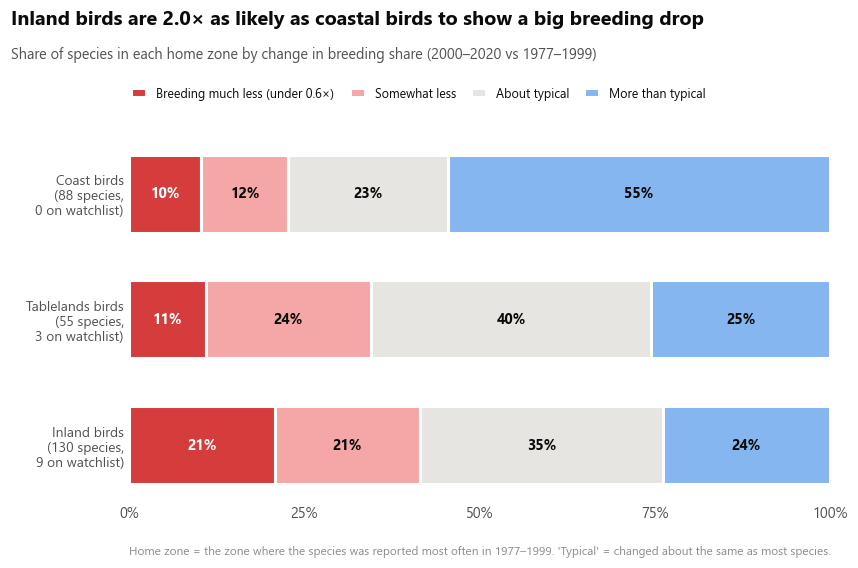

In [14]:
def chart_q4(fig):
    ratio = mix.loc["Inland", "much_less"] / mix.loc["Coast", "much_less"]
    headline(fig, f"Inland birds are {ratio:.1f}× as likely as coastal birds to show a big breeding drop",
             "Share of species in each home zone by change in breeding share (2000–2020 vs 1977–1999)")
    ax = fig.add_gridspec(1, 1, left=0.20, right=0.97, top=0.76, bottom=0.15).subplots()
    colors = [DIV["much_less"], DIV["less"], DIV["typical"], DIV["more"]]
    left = np.zeros(3)
    for gname, c, lab in zip(GROUPS, colors, GROUP_LABEL):
        vals = mix[gname].values
        ax.barh(range(3), vals, left=left, color=c, height=0.62, edgecolor="white", lw=2, label=lab)
        for i, (l, v) in enumerate(zip(left, vals)):
            if v >= 6:
                ax.text(l + v / 2, i, f"{v:.0f}%", ha="center", va="center", fontsize=9.5,
                        color="white" if gname == "much_less" else INK, fontweight="bold")
        left += vals
    ax.set_yticks(range(3), [f"{z} birds\n({counts[z]} species,\n{watch_home[z]} on watchlist)" for z in ZONE_ORDER],
                  fontsize=9)
    ax.invert_yaxis(); ax.set_xlim(0, 100)
    ax.set_xticks([0, 25, 50, 75, 100], ["0%", "25%", "50%", "75%", "100%"]); ax.grid(False)
    ax.spines["left"].set_visible(False); ax.spines["bottom"].set_visible(False)
    fig.legend(loc="upper left", bbox_to_anchor=(0.19, 0.865), ncol=4, fontsize=8.2, handlelength=1.2,
               columnspacing=1.2)
    fig.text(0.20, 0.06, "Home zone = the zone where the species was reported most often in 1977–1999. "
             "'Typical' = changed about the same as most species.", fontsize=7.8, color=MUTED)

show(chart_q4, "Q4_zone_comparison")

In [15]:
worse = mix["much_less"] + mix["less"]
Q4 = dict(
    question="Are birds of the inland faring worse than coastal and tablelands birds?",
    why="If declines are concentrated in one group of birds, it points to a shared pressure and suggests "
        "protecting that group's habitat as a whole rather than one species at a time.",
    findings=[
        f"{mix.loc['Inland', 'much_less']:.0f}% of inland species show a big breeding drop, compared with "
        f"{mix.loc['Tablelands', 'much_less']:.0f}% of tablelands species and {mix.loc['Coast', 'much_less']:.0f}% "
        f"of coastal species.",
        f"Counting any drop below typical: inland {worse['Inland']:.0f}%, tablelands {worse['Tablelands']:.0f}%, "
        f"coast {worse['Coast']:.0f}%.",
        f"{watch_home['Inland']} of the {len(watch)} watchlist species from Q1 are inland birds.",
        f"Coastal birds mostly held up: {mix.loc['Coast', 'more']:.0f}% bred more than the typical species.",
    ],
    meaning="Inland woodland and open-country birds are the group most in need of attention. Protecting and "
            "restoring inland woodland habitat could benefit several at-risk species at once.",
    caveat="Home zone is a simple label; many species occur in more than one zone. Weather and drought data "
           "have not yet been supplied, so drought effects cannot be separated out.",
)
display(Markdown("### Answer\n" + "\n".join(f"* {f}" for f in Q4["findings"]) +
                 f"\n\n**What it means:** {Q4['meaning']}\n\n*Caution: {Q4['caveat']}*"))

### Answer
* 21% of inland species show a big breeding drop, compared with 11% of tablelands species and 10% of coastal species.
* Counting any drop below typical: inland 42%, tablelands 35%, coast 23%.
* 9 of the 12 watchlist species from Q1 are inland birds.
* Coastal birds mostly held up: 55% bred more than the typical species.

**What it means:** Inland woodland and open-country birds are the group most in need of attention. Protecting and restoring inland woodland habitat could benefit several at-risk species at once.

*Caution: Home zone is a simple label; many species occur in more than one zone. Weather and drought data have not yet been supplied, so drought effects cannot be separated out.*

---
## Q5. Are we still monitoring enough to notice a species in decline?

**Why ask this.** Every answer above depends on people going out and surveying. If monitoring has thinned,
a species could decline without anyone noticing — and the gaps on the Q2 map would keep growing.

**How we measured it.** Survey sheets (Atlas + DES), the number of different observers, and the number of
ten-minute grid squares surveyed, per year from 1977 to 2025.

In [16]:
q5 = surveys[surveys["year"].between(1977, 2025)].drop_duplicates("sheet_id")
q5 = q5.assign(square=q5["klat"] * 100000 + q5["klon"])
yearly = q5.groupby(["year", "source"], observed=True).agg(
    sheets=("sheet_id", "size"), observers=("observer_id", "nunique"), squares=("square", "nunique")).reset_index()
yearly["year"] = yearly["year"].astype(int)
totals = q5.groupby("year").agg(sheets=("sheet_id", "size"), observers=("observer_id", "nunique"),
                                squares=("square", "nunique"))
totals.index = totals.index.astype(int)
yearly.to_csv(OUTPUT_DIR / "Q5_monitoring_by_year.csv", index=False)

recent_years = q5[q5["year"] >= 2021]
top5_share = recent_years["observer_id"].value_counts().head(5).sum() / len(recent_years)
base = totals.loc[EARLY[0]:EARLY[1]].mean()        # long-run average, avoids the one-off 1999-2001 survey spike
late = totals.loc[2021:2025].mean()
drop = 1 - late / base
display(pd.DataFrame({f"average {EARLY[0]}-{str(EARLY[1])[2:]}": base.round(0), "average 2021-25": late.round(0),
                      "drop": drop.map("{:.0%}".format)}))
print(f"Top 5 observers supplied {top5_share:.0%} of survey sheets in 2021-2025.")

,average 1977-99,average 2021-25,drop
sheets,5702.0,462.0,92%
observers,174.0,38.0,78%
squares,1127.0,230.0,80%


Top 5 observers supplied 37% of survey sheets in 2021-2025.


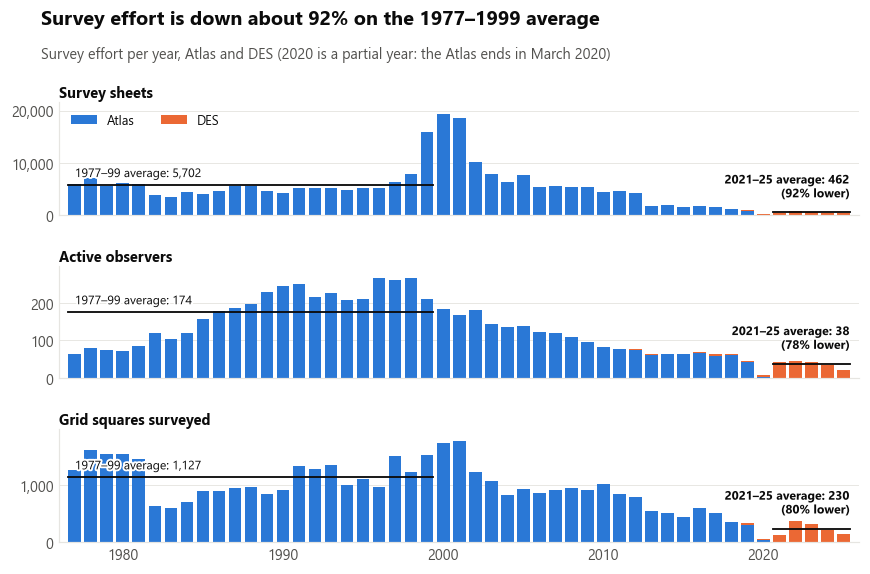

In [17]:
def chart_q5(fig):
    headline(fig, f"Survey effort is down about {drop['sheets']:.0%} on the {EARLY[0]}–{EARLY[1]} average",
             "Survey effort per year, Atlas and DES (2020 is a partial year: the Atlas ends in March 2020)")
    axes = fig.add_gridspec(3, 1, left=0.09, right=0.97, top=0.82, bottom=0.08, hspace=0.45).subplots(sharex=True)
    metrics = [("sheets", "Survey sheets"), ("observers", "Active observers"), ("squares", "Grid squares surveyed")]
    for ax, (m, label) in zip(axes, metrics):
        piv = yearly.pivot(index="year", columns="source", values=m).reindex(range(1977, 2026)).fillna(0)
        ax.bar(piv.index, piv.get("Atlas", 0), color=BLUE, width=0.8, label="Atlas")
        ax.bar(piv.index, piv.get("DES", 0), bottom=piv.get("Atlas", 0), color=ORANGE, width=0.8, label="DES")
        ax.set_title(label, loc="left", fontsize=9.5, color=INK, fontweight="bold", pad=3)
        ax.yaxis.set_major_formatter(mpl.ticker.FuncFormatter(lambda v, _: f"{v:,.0f}"))
        ax.grid(axis="x", visible=False)
        ax.locator_params(axis="y", nbins=3)
        pv = totals[m].max()
        halo = [mpl.patheffects.withStroke(linewidth=2.5, foreground="white")]
        ax.plot([EARLY[0] - 0.4, EARLY[1] + 0.4], [base[m]] * 2, color=INK, lw=1.2)
        ax.text(EARLY[0], base[m] + pv * 0.05, f"{EARLY[0]}–{str(EARLY[1])[2:]} average: {base[m]:,.0f}", fontsize=8,
                color=INK, va="bottom", path_effects=halo)
        ax.plot([2020.6, 2025.4], [late[m]] * 2, color=INK, lw=1.2)
        ax.text(2025.4, late[m] + pv * 0.12, f"2021–25 average: {late[m]:,.0f}\n({drop[m]:.0%} lower)", fontsize=8,
                color=INK, ha="right", va="bottom", fontweight="bold", path_effects=halo)
        ax.set_ylim(0, pv * 1.12)
    axes[0].legend(loc="upper left", ncol=2, fontsize=8.5, bbox_to_anchor=(0.0, 1.0))
    axes[-1].set_xlim(1976, 2026)

show(chart_q5, "Q5_monitoring_effort")

In [18]:
Q5 = dict(
    question="Are we still monitoring enough to notice a species in decline?",
    why="Every other answer depends on people surveying. If monitoring thins out, a species can decline "
        "without anyone noticing — the earlier warning signs in Q1 to Q4 would simply go unseen.",
    findings=[
        f"Survey sheets averaged {base['sheets']:,.0f} a year in {EARLY[0]}–{EARLY[1]} but only {late['sheets']:,.0f} "
        f"a year in 2021–2025 — about {drop['sheets']:.0%} lower.",
        f"Active observers fell from about {base['observers']:,.0f} a year to about {late['observers']:,.0f} "
        f"({drop['observers']:.0%} lower).",
        f"Grid squares surveyed fell from about {base['squares']:,.0f} a year to about {late['squares']:,.0f} "
        f"({drop['squares']:.0%} lower), so much of NSW now goes unvisited in a typical year.",
        f"The recent record leans on a few people: the top 5 observers supplied {top5_share:.0%} of survey sheets "
        f"in 2021–2025.",
    ],
    meaning="Current monitoring is too thin to track most species reliably. Rebuilding a volunteer network, "
            "with repeat visits to the watchlist species' strongholds and inland cells, is likely the single "
            "most important step for early detection.",
    caveat="DES is a different recording system from the Atlas; here it is only used to count survey effort.",
)
display(Markdown("### Answer\n" + "\n".join(f"* {f}" for f in Q5["findings"]) +
                 f"\n\n**What it means:** {Q5['meaning']}\n\n*Caution: {Q5['caveat']}*"))

### Answer
* Survey sheets averaged 5,702 a year in 1977–1999 but only 462 a year in 2021–2025 — about 92% lower.
* Active observers fell from about 174 a year to about 38 (78% lower).
* Grid squares surveyed fell from about 1,127 a year to about 230 (80% lower), so much of NSW now goes unvisited in a typical year.
* The recent record leans on a few people: the top 5 observers supplied 37% of survey sheets in 2021–2025.

**What it means:** Current monitoring is too thin to track most species reliably. Rebuilding a volunteer network, with repeat visits to the watchlist species' strongholds and inland cells, is likely the single most important step for early detection.

*Caution: DES is a different recording system from the Atlas; here it is only used to count survey effort.*

---
## Summary — what this means for protecting bird species

In [19]:
SUMMARY = [
    ("Who", f"{len(watch)} species are seen less often and breed less when seen — a watchlist for follow-up "
            f"(named on the Question 1 page)."),
    ("Where", f"Breeding faded more than the NSW trend in {by_zone['Inland']:.0f}% of inland and "
              f"{by_zone['Tablelands']:.0f}% of tablelands areas, vs {by_zone['Coast']:.0f}% on the coast; "
              f"{len(held)} areas held up and may act as refuges."),
    ("When", f"Most species nest {busy[0]}–{busy[-1]}. {quiet[0]}–{quiet[-1]} is the quiet window for planned "
             f"disturbance such as burns or clearing."),
    ("Which group", f"Inland birds are the group most affected: {mix.loc['Inland', 'much_less']:.0f}% show a big "
                    f"breeding drop vs {mix.loc['Coast', 'much_less']:.0f}% of coastal birds."),
    ("Can we see it", f"Survey effort is down about {drop['sheets']:.0%} on the {EARLY[0]}–{EARLY[1]} average, "
                      f"with only ~{late['observers']:.0f} active observers a year."),
]
NEXT_STEPS = [
    "Check the watchlist against official threatened-species listings and prioritise species not yet listed.",
    "Target new surveys (including nest checks) at the faded inland cells and at the strongholds that held up.",
    f"Recommend timing planned burns and clearing for {quiet[0]}–{quiet[-1]} where practical.",
    "Rebuild the volunteer monitoring network, with repeat visits to the same sites each spring.",
    "Add rainfall/drought and land-cover data so that possible causes can be tested.",
]
display(Markdown("\n".join(f"* **{k}:** {v}" for k, v in SUMMARY) + "\n\n**Suggested next steps**\n" +
                 "\n".join(f"{i}. {s}" for i, s in enumerate(NEXT_STEPS, 1))))

* **Who:** 12 species are seen less often and breed less when seen — a watchlist for follow-up (named on the Question 1 page).
* **Where:** Breeding faded more than the NSW trend in 64% of inland and 61% of tablelands areas, vs 21% on the coast; 56 areas held up and may act as refuges.
* **When:** Most species nest Oct–Jan. Mar–Jul is the quiet window for planned disturbance such as burns or clearing.
* **Which group:** Inland birds are the group most affected: 21% show a big breeding drop vs 10% of coastal birds.
* **Can we see it:** Survey effort is down about 92% on the 1977–1999 average, with only ~38 active observers a year.

**Suggested next steps**
1. Check the watchlist against official threatened-species listings and prioritise species not yet listed.
2. Target new surveys (including nest checks) at the faded inland cells and at the strongholds that held up.
3. Recommend timing planned burns and clearing for Mar–Jul where practical.
4. Rebuild the volunteer monitoring network, with repeat visits to the same sites each spring.
5. Add rainfall/drought and land-cover data so that possible causes can be tested.

---
## Build the client PDF
This cell lays out a cover page, one page per question (question → chart → answer) and a summary page,
using the same charts and text as above. Re-run it after changing any setting.

In [20]:
import logging
logging.getLogger("fontTools").setLevel(logging.ERROR)
A4 = (8.27, 11.69)

def wrap_lines(fig, x, y, text, size=10, width=95, color=INK, weight="normal", indent="", gap=1.35, style="normal"):
    # Writes wrapped text from y (inches from the top) downward; returns the new y
    lines = textwrap.wrap(text, width=width, subsequent_indent=indent)
    for line in lines:
        fig.text(x / A4[0], 1 - y / A4[1], line, fontsize=size, color=color, fontweight=weight, va="top",
                 fontstyle=style)
        y += size * gap / 72
    return y

def page_frame(fig, number, total, tag):
    fig.add_artist(Rectangle((0, 1 - 0.32 / A4[1]), 1, 0.32 / A4[1], transform=fig.transFigure, color=BLUE, lw=0))
    fig.text(0.6 / A4[0], 1 - 0.16 / A4[1], f"{REPORT_TITLE}  ·  {tag}", fontsize=8.5, color="white",
             va="center", fontweight="bold")
    fig.text(1 - 0.6 / A4[0], 0.35 / A4[1], f"{number} / {total}", fontsize=8, color=MUTED, ha="right")
    fig.text(0.6 / A4[0], 0.35 / A4[1], "Associations only — patterns in the records, not proven causes.",
             fontsize=7.5, color=MUTED)

def question_page(pdf, num, Q, chart, number, total):
    fig = plt.figure(figsize=A4)
    page_frame(fig, number, total, f"Question {num}")
    y = 0.75
    fig.text(0.6 / A4[0], 1 - y / A4[1], f"RESEARCH QUESTION {num}", fontsize=9, color=BLUE, fontweight="bold", va="top")
    y = wrap_lines(fig, 0.6, y + 0.22, Q["question"], size=16, width=62, weight="bold", gap=1.25)
    y = wrap_lines(fig, 0.6, y + 0.08, "Why this matters: " + Q["why"], size=9.5, width=112, color=INK2)
    top, bottom = y + 0.15, y + 0.15 + 5.15
    # Subfigures fill their grid row, so the chart area is the middle row of a three-row split of the page
    sub = fig.subfigures(3, 1, height_ratios=[top, bottom - top, A4[1] - bottom], hspace=0)[1]
    sub.set_facecolor("none")
    chart(sub)
    y = bottom + 0.2
    fig.text(0.6 / A4[0], 1 - y / A4[1], "ANSWER", fontsize=9, color=BLUE, fontweight="bold", va="top")
    y += 0.25
    for f in Q["findings"]:
        fig.text(0.62 / A4[0], 1 - y / A4[1], "•", fontsize=10, color=BLUE, va="top")
        y = wrap_lines(fig, 0.82, y, f, size=9.8, width=108) + 0.05
    box_top = y + 0.1
    yy = wrap_lines(fig, 0.75, box_top + 0.14, "What it means: " + Q["meaning"], size=9.8, width=100, weight="bold")
    fig.add_artist(Rectangle((0.6 / A4[0], 1 - (yy + 0.1) / A4[1]), 1 - 1.2 / A4[0], (yy + 0.1 - box_top) / A4[1],
                             transform=fig.transFigure, color="#eef4fc", lw=0, zorder=0))
    wrap_lines(fig, 0.6, yy + 0.25, "Caution: " + Q["caveat"], size=8.5, width=125, color=INK2, style="italic")
    pdf.savefig(fig); plt.close(fig)

def cover_page(pdf, total):
    fig = plt.figure(figsize=A4)
    fig.add_artist(Rectangle((0, 0.62), 1, 0.38, transform=fig.transFigure, color=BLUE, lw=0))
    fig.text(0.08, 0.86, REPORT_TITLE, fontsize=26, color="white", fontweight="bold")
    fig.text(0.08, 0.82, REPORT_SUBTITLE, fontsize=14, color="white")
    fig.text(0.08, 0.70, f"{PREPARED_FOR}  ·  {PREPARED_BY}  ·  {pd.Timestamp.today():%d %B %Y}", fontsize=9.5,
             color="white")
    fig.text(0.08, 0.66, f"Data: NSW Bird Atlas ({EARLY[0]}–{RECENT[1]}) and DES backlog (to 2025)", fontsize=9.5,
             color="white")
    y = 4.9
    fig.text(0.6 / A4[0], 1 - y / A4[1], "THE FIVE QUESTIONS", fontsize=10, color=BLUE, fontweight="bold", va="top")
    y += 0.35
    for i, (k, v) in enumerate(SUMMARY, 1):
        Q = [Q1, Q2, Q3, Q4, Q5][i - 1]
        fig.text(0.6 / A4[0], 1 - y / A4[1], f"Q{i}", fontsize=13, color=BLUE, fontweight="bold", va="top")
        y = wrap_lines(fig, 1.15, y, Q["question"], size=11, width=80, weight="bold")
        y = wrap_lines(fig, 1.15, y + 0.02, v, size=9.5, width=95, color=INK2) + 0.22
    y += 0.1
    fig.text(0.6 / A4[0], 1 - y / A4[1], "HOW TO READ THIS REPORT", fontsize=10, color=BLUE, fontweight="bold", va="top")
    y = wrap_lines(fig, 0.6, y + 0.3, "Each page asks one research question, answers it with a chart, and explains "
                   "what it means for protecting species. Because the way breeding was recorded changed over time, "
                   "species and places are compared with the typical NSW trend, not with raw totals.",
                   size=9.5, width=112, color=INK2)
    fig.text(1 - 0.6 / A4[0], 0.35 / A4[1], f"1 / {total}", fontsize=8, color=MUTED, ha="right")
    pdf.savefig(fig); plt.close(fig)

def summary_page(pdf, number, total):
    fig = plt.figure(figsize=A4)
    page_frame(fig, number, total, "Summary")
    y = 0.75
    fig.text(0.6 / A4[0], 1 - y / A4[1], "SUMMARY", fontsize=9, color=BLUE, fontweight="bold", va="top")
    y = wrap_lines(fig, 0.6, y + 0.22, "What this means for protecting bird species", size=16, width=62, weight="bold")
    y += 0.2
    for k, v in SUMMARY:
        fig.text(0.6 / A4[0], 1 - y / A4[1], k, fontsize=10.5, color=BLUE, fontweight="bold", va="top")
        y = wrap_lines(fig, 1.9, y, v, size=10, width=92) + 0.18
    y += 0.25
    fig.text(0.6 / A4[0], 1 - y / A4[1], "SUGGESTED NEXT STEPS", fontsize=9, color=BLUE, fontweight="bold", va="top")
    y += 0.3
    for i, s in enumerate(NEXT_STEPS, 1):
        fig.text(0.62 / A4[0], 1 - y / A4[1], f"{i}.", fontsize=10, color=BLUE, fontweight="bold", va="top")
        y = wrap_lines(fig, 0.9, y, s, size=10, width=104) + 0.12
    y += 0.3
    fig.text(0.6 / A4[0], 1 - y / A4[1], "ABOUT THE DATA AND METHOD", fontsize=9, color=BLUE, fontweight="bold", va="top")
    y += 0.3
    notes = [
        f"Records: {len(data):,} usable species records from the NSW Bird Atlas and the DES backlog. eBird is "
        f"excluded, as agreed with the client.",
        f"Q1–Q4 compare the Atlas with itself, {EARLY[0]}–{EARLY[1]} vs {RECENT[0]}–{RECENT[1]}, using surveys only. "
        f"Atlas and DES rates are never mixed because they recorded breeding differently.",
        "Breeding was recorded less often overall in recent years, so each species and place is compared with the "
        "typical change rather than raw totals.",
        f"Q1 includes species with at least {MIN_SIGHTINGS} sightings in each period and {MIN_EARLY_BREEDING} early "
        f"breeding records. A drop is 'clear' when it is unlikely to be chance after allowing for testing many species.",
        "All settings (periods, thresholds, map cell size) can be changed in the accompanying notebook.",
    ]
    for n in notes:
        fig.text(0.62 / A4[0], 1 - y / A4[1], "•", fontsize=9, color=MUTED, va="top")
        y = wrap_lines(fig, 0.82, y, n, size=8.8, width=120, color=INK2) + 0.06
    pdf.savefig(fig); plt.close(fig)

pdf_path = OUTPUT_DIR / PDF_NAME
pages = [(Q1, chart_q1), (Q2, chart_q2), (Q3, chart_q3), (Q4, chart_q4), (Q5, chart_q5)]
total = len(pages) + 2
with PdfPages(pdf_path) as pdf:
    cover_page(pdf, total)
    for i, (Q, chart) in enumerate(pages, 1):
        question_page(pdf, i, Q, chart, i + 1, total)
    summary_page(pdf, total, total)
    info = pdf.infodict()
    info["Title"] = f"{REPORT_TITLE} — {REPORT_SUBTITLE}"
    info["Author"] = PREPARED_BY
print("PDF written to", pdf_path.resolve())

PDF written to C:\Users\pup\Documents\Work\Code\capstone\client_insights\outputs\Bird_Breeding_Insights_Report.pdf
